## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from datasets.code.helper import get_altimetry_obs, get_wl_point_obs, get_u_v_point_obs

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.tshred.TSHRED import TSHRED, fit
from src.shred.SHRED import SHRED, fit as fit_s


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

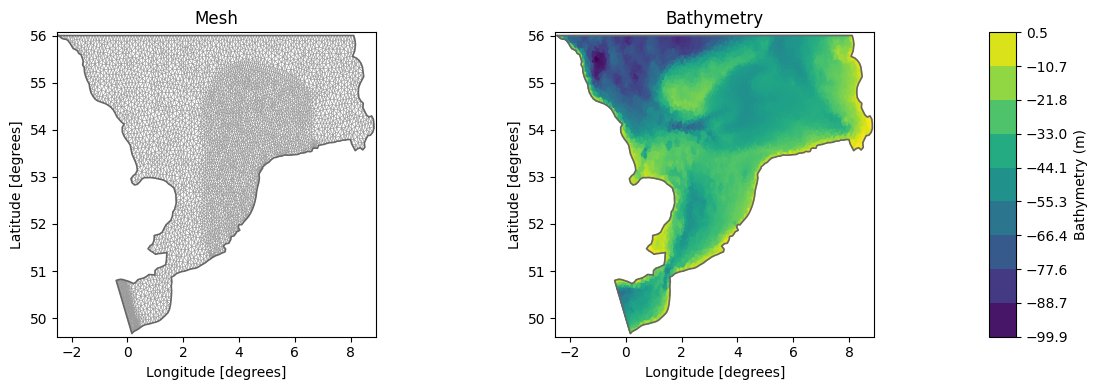

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

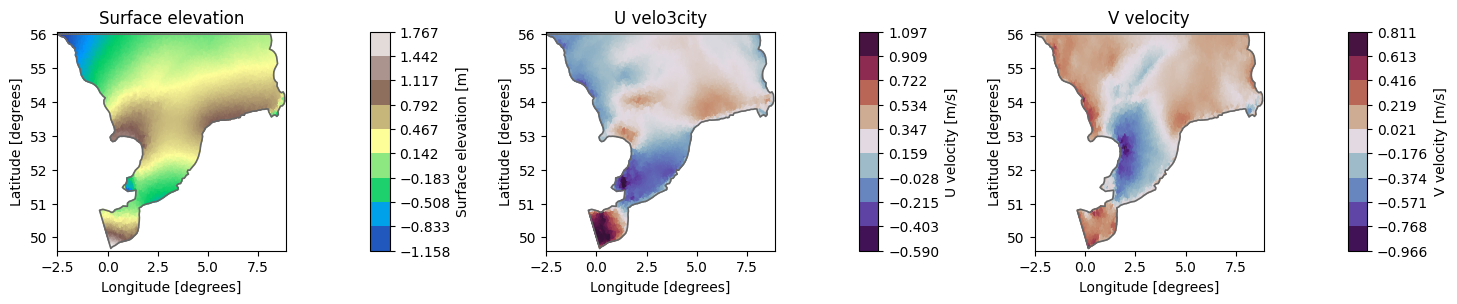

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


<Axes: >

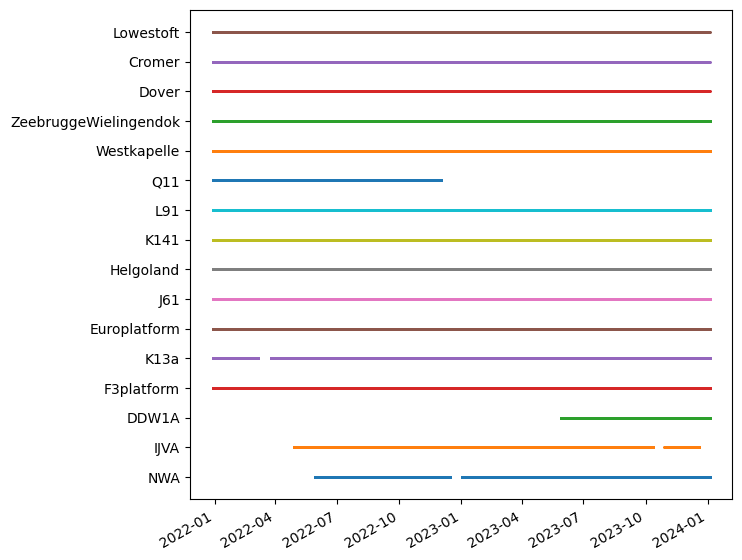

In [6]:
# sensor coverage

wllist = get_wl_point_obs()
ms.plotting.temporal_coverage(wllist)

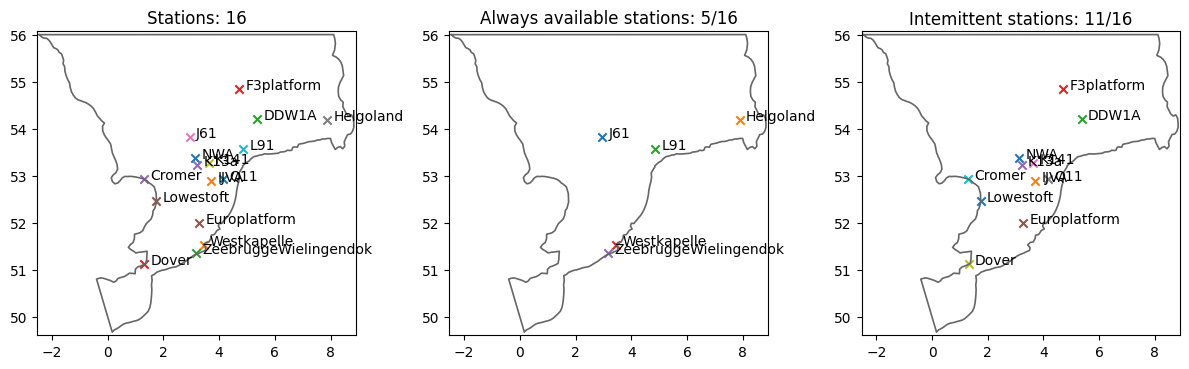

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(wllist)):
    stations.append(wllist[i])
    if ds.time.isin(wllist[i].time).all():
        availables.append(wllist[i])
    else:
        intermittent.append(wllist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intemittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements

measurements = np.full((ds.time.shape[0], len(stations)), np.nan)

for i in range(len(stations)):
    
    stn_data = pd.read_csv(obs_fldr + stations[i].name + "_wl.csv", index_col = 0)
    measurements[:,i] = stn_data["water_level_filtered"].reindex(ds.time.strftime("%Y-%m-%d %H:%M:%S")).values 

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 16])


## Idea 0: Only Available Sensors

In [10]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in availables]
measurements_av = measurements[:, av_indices]

#counts nans
nan_counts_available = np.isnan(measurements_av.numpy()).sum(axis=0)
nan_counts_intermittent = np.isnan(measurements[:, [stations.index(s) for s in intermittent]].numpy()).sum(axis=0)

#available stations
print("Available stations:\n", [f"{s.name}: {nan_counts_available[i]}" for i, s in enumerate(availables)])
print("Intermittent stations:\n", [f"{s.name}: {nan_counts_intermittent[i]}" for i, s in enumerate(intermittent)])

# print the shape of the arrays
print("\nAfter selecting always-available stations only:")
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements_av.shape)

Available stations:
 ['J61: 0', 'Helgoland: 0', 'L91: 0', 'Westkapelle: 0', 'ZeebruggeWielingendok: 0']
Intermittent stations:
 ['NWA: 8570', 'IJVA: 8296', 'DDW1A: 25127', 'F3platform: 18', 'K13a: 1151', 'Europlatform: 435', 'K141: 67', 'Q11: 19139', 'Dover: 18015', 'Cromer: 18320', 'Lowestoft: 18051']

After selecting always-available stations only:
H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 5])


In [11]:
# Data manager

lags = 48
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 100, measurements = measurements_av)
manager.add_data(U, id = "U velocity", compress = 100)
manager.add_data(V, id = "V velocity", compress = 100)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare()

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements_av.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)



Input shape for the model: 5
Output shape for the model: 300


Training: 100%|██████████| 100/100 [09:14<00:00,  5.54s/it, Train Error=10.926%, Val Error=11.911%, Patience=28, Best Val Error=11.881%, LR=2.50e-04]

Training Complete (100 epochs)


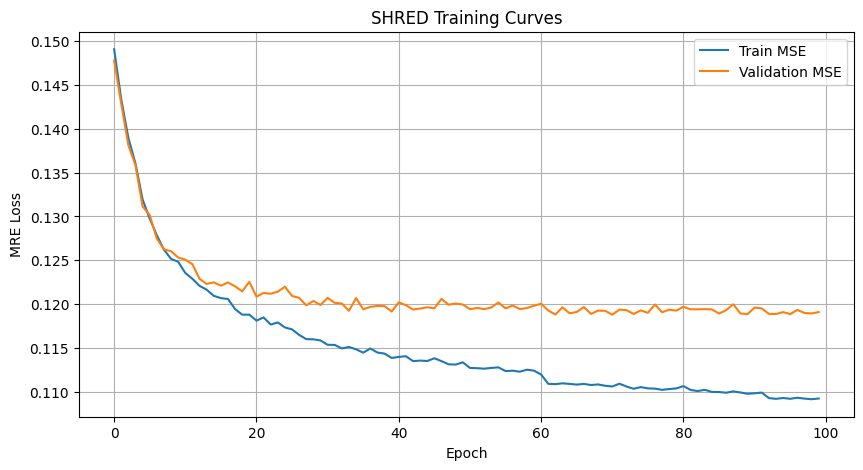

In [14]:
# Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_args = dict(
    # Encoder
    encoder         = "vanilla_transformer",
    encoder_depth   = 2,
    d_model         = nn_input_shape,
    n_heads         = 4,
    dim_feedforward = 64,
    hidden_size     = 32,         # must be divisible by n_heads (32 / 4 = 8 ✓)
    input_length    = lags,

    # Decoder
    decoder         = "cnn",
    decoder_depth   = 2,
    output_size     = nn_output_shape,

    # Shared
    dropout         = 0.0,
    device          = device,
)
tshred = TSHRED(args=model_args)

# Train the model
train_errors, valid_errors = fit(
    tshred, train_dataset, val_dataset, 
    batch_size = 64, epochs = 100, lr = 1e-3, verbose = True, patience = 30, scheduler_patience=20
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MRE Loss')
plt.title('SHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

Training: 100%|██████████| 100/100 [12:41<00:00,  7.61s/it, Train Error=8.743%, Val Error=12.326%, Patience=63]

Training Complete (100 epochs)


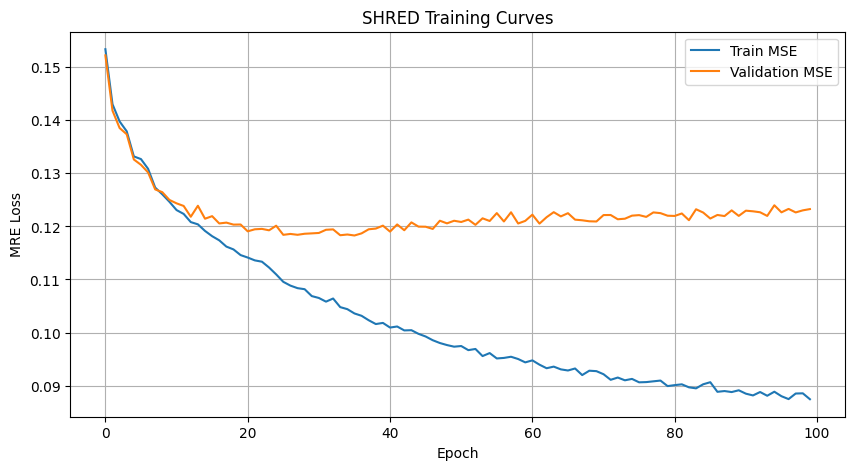

In [ ]:
# SHRED TRAINING
import functools
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
shred = SHRED(
    nn_input_shape, nn_output_shape, hidden_size = 64, 
    hidden_layers = 2, dropout = 0.1
).to(device)
train_errors, valid_errors = fit_s(
    shred, train_dataset, val_dataset, 
    batch_size = 64, epochs = 100, lr = 1e-3,
    optimizer = functools.partial(torch.optim.AdamW, weight_decay = 0.01),
    verbose = True, patience = 20
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MRE Loss')
plt.title('SHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

In [ ]:
engine = SHREDEngine(manager, shred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)

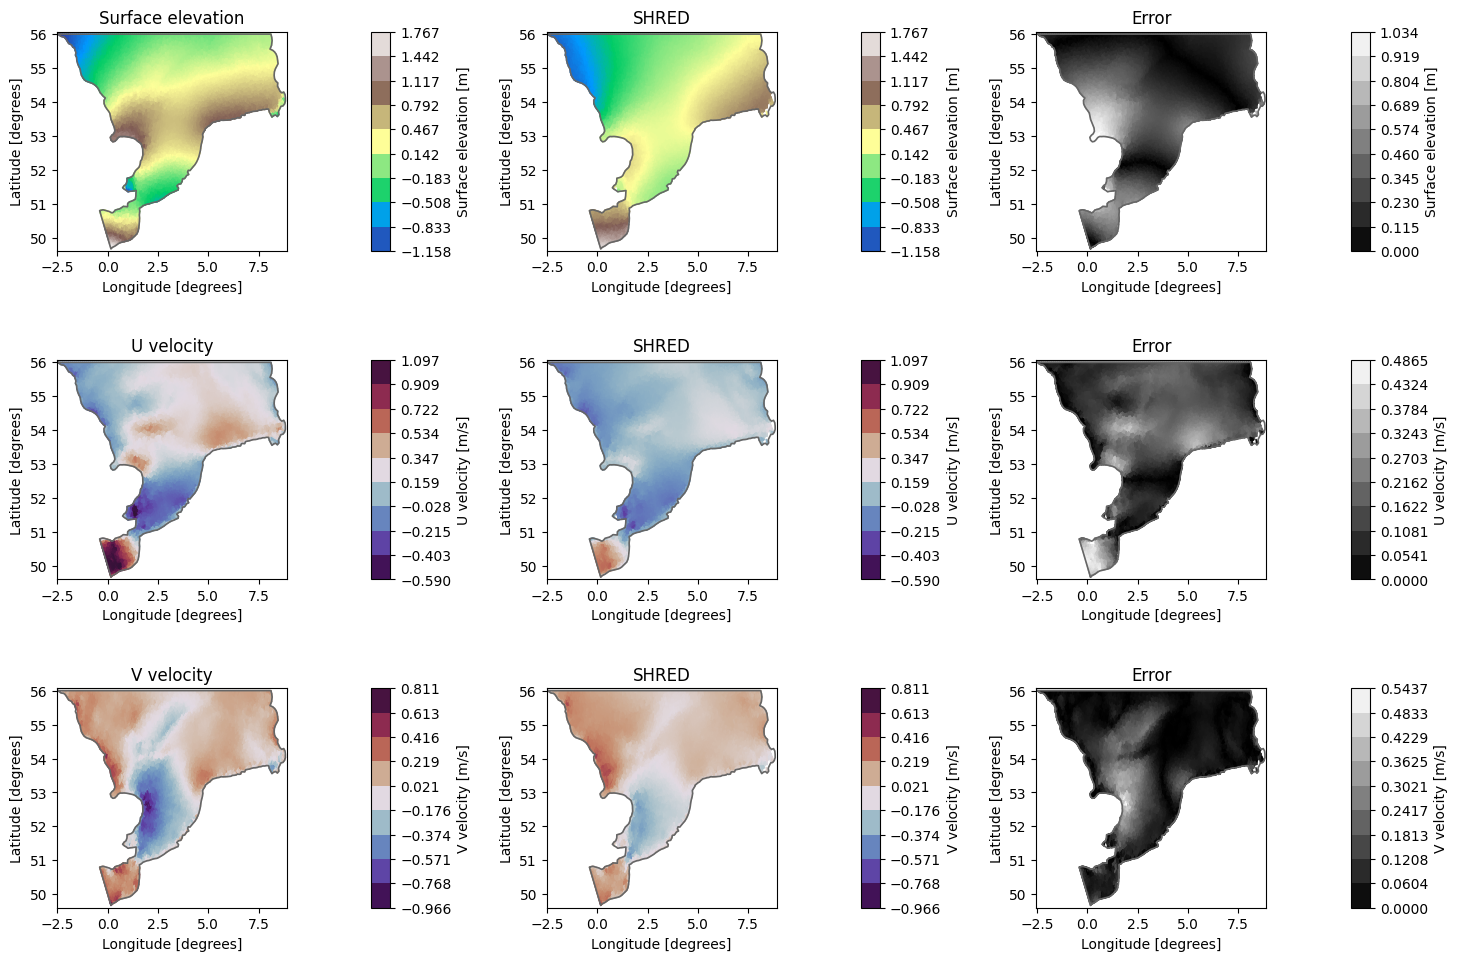

In [ ]:
# Build datasets with SHRED reconstructions and errors (filling NaN locations for plotting)

times_test = ds.time[-test_reconstruction["Surface elevation"].shape[0]:]

H_reconstruction = np.full((test_reconstruction["Surface elevation"].shape[0], ds["Surface elevation"].values.shape[1]), np.nan)
H_reconstruction[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)] = test_reconstruction["Surface elevation"]

U_reconstruction = np.full((test_reconstruction["U velocity"].shape[0], ds["U velocity"].values.shape[1]), np.nan)
U_reconstruction[:,~np.isnan(ds["U velocity"].values).any(axis=0)] = test_reconstruction["U velocity"]

V_reconstruction = np.full((test_reconstruction["V velocity"].shape[0], ds["V velocity"].values.shape[1]), np.nan)
V_reconstruction[:,~np.isnan(ds["V velocity"].values).any(axis=0)] = test_reconstruction["V velocity"]

ds_shred = mikeio.Dataset([
    mikeio.DataArray(data=H_reconstruction, time=times_test, item=ds.items[0], geometry=geom),
    mikeio.DataArray(data=U_reconstruction, time=times_test, item=ds.items[1], geometry=geom),
    mikeio.DataArray(data=V_reconstruction, time=times_test, item=ds.items[2], geometry=geom),
])

ds_error = mikeio.Dataset([
    mikeio.DataArray(data=np.sqrt((ds["Surface elevation"].sel(time=times_test).values - ds_shred["Surface elevation"].values)**2), time=times_test, item=ds.items[0], geometry=geom),
    mikeio.DataArray(data=np.sqrt((ds["U velocity"].sel(time=times_test).values - ds_shred["U velocity"].values)**2),          time=times_test, item=ds.items[1], geometry=geom),
    mikeio.DataArray(data=np.sqrt((ds["V velocity"].sel(time=times_test).values - ds_shred["V velocity"].values)**2),          time=times_test, item=ds.items[2], geometry=geom),
])

# Qualitative comparison

plot_time = ds_shred.time[-1]
fig,axs = plt.subplots(3, 3, figsize=(15,10))
vmin = min(np.nanmin(ds["Surface elevation"].sel(time=plot_time).values), np.nanmin(ds_shred["Surface elevation"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["Surface elevation"].sel(time=plot_time).values), np.nanmax(ds_shred["Surface elevation"].sel(time=plot_time).values))
ds["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,0], title="Surface elevation", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_shred["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,1], title="SHRED", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_error["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["U velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["U velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["U velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["U velocity"].sel(time=plot_time).values))
ds["U velocity"].sel(time=plot_time).plot(ax=axs[1,0], title="U velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["U velocity"].sel(time=plot_time).plot(ax=axs[1,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["U velocity"].sel(time=plot_time).plot(ax=axs[1,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["V velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["V velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["V velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["V velocity"].sel(time=plot_time).values))
ds["V velocity"].sel(time=plot_time).plot(ax=axs[2,0], title="V velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["V velocity"].sel(time=plot_time).plot(ax=axs[2,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["V velocity"].sel(time=plot_time).plot(ax=axs[2,2], title="Error", cmap = "gray")

plt.tight_layout()
plt.show()
